In [20]:
from starter.load_atd import load as load_atd
import games
from kloppy import sportscode
import pandas as pd
import os, sys
import evaluation.possession_metrics as pm
import matplotlib.pyplot as plt
import starter.baseline as base
import numpy as np
from matplotlib.ticker import MultipleLocator

In [21]:
ball_and_player_positions = load_atd()
ball_and_player_positions_df = ball_and_player_positions.to_df()
print(ball_and_player_positions_df.head())
path = games.asset_paths()['smart_tagging']
events = sportscode.load(path).to_df()
print(events.head())

   period_id              timestamp  frame_id ball_state ball_owning_team_id  \
0          1 0 days 00:00:00.040000         1       None                None   
1          1 0 days 00:00:00.080000         2       None                None   
2          1 0 days 00:00:00.120000         3       None                None   
3          1 0 days 00:00:00.160000         4       None                None   
4          1 0 days 00:00:00.200000         5       None                None   

   ball_x  ball_y ball_z ball_speed      1_x  ...  44_d 44_s  45_x  45_y  \
0     NaN     NaN   None       None  0.33411  ...  None  NaN   NaN   NaN   
1     NaN     NaN   None       None  0.33404  ...  None  NaN   NaN   NaN   
2     NaN     NaN   None       None  0.33396  ...  None  NaN   NaN   NaN   
3     NaN     NaN   None       None  0.33389  ...  None  NaN   NaN   NaN   
4     NaN     NaN   None       None  0.33382  ...  None  NaN   NaN   NaN   

   45_d 45_s     46_x     46_y  46_d 46_s  
0  None  NaN  0.06

In [22]:
filtered_ball_and_player_positions_df = ball_and_player_positions_df[
    ((ball_and_player_positions_df["ball_x"].notna()) | (ball_and_player_positions_df["ball_y"].notna())) &
    (ball_and_player_positions_df["frame_id"] > 11184)
]

In [23]:
negative_ball_positions_df = filtered_ball_and_player_positions_df[
    (filtered_ball_and_player_positions_df["ball_x"] < 0) |
    (filtered_ball_and_player_positions_df["ball_y"] < 0) |
    (filtered_ball_and_player_positions_df["ball_x"] > 1) |
    (filtered_ball_and_player_positions_df["ball_y"] > 1)
]

In [24]:
cols = ['ball_x', 'ball_y']
tolerance = 0.0001

groups = []
current_group = []

reference = None
current_period = None

for row in ball_and_player_positions_df[['period_id', 'frame_id', 'timestamp'] + cols].itertuples(index=False):

    period_id, frame_id, timestamp, x, y = row
    position = np.array([x, y], dtype=float)

    # Zmiana połowy meczu
    if current_period is not None and period_id != current_period:
        if current_group:
            groups.append(current_group)

        current_group = []
        reference = None

    current_period = period_id

    # Klatka z całkowitym brakiem danych
    if np.isnan(position).all():
        if reference is not None:
            current_group.append((frame_id, timestamp, x, y))
        continue

    # Pierwsza pozycja w ciągu
    if reference is None:
        reference = position.copy()
        current_group = [(frame_id, timestamp, x, y)]
        continue

    # Porównanie z pierwszą pozycją
    # NaN w pojedynczej współrzędnej nie przerywa ciągu
    comparable = ~np.isnan(position) & ~np.isnan(reference)

    is_close = (
        np.any(comparable) and
        np.all(np.abs(position[comparable] - reference[comparable]) <= tolerance)
    )

    if is_close:
        current_group.append((frame_id, timestamp, x, y))
    else:
        groups.append(current_group)

        reference = position.copy()
        current_group = [(frame_id, timestamp, x, y)]

# Ostatni ciąg
if current_group:
    groups.append(current_group)


results = []

for group in groups:

    # Pomijamy krótsze niż 2 sekundy
    if len(group) < 50:
        continue

    results.append({
        'start_frame': group[0][0],
        'end_frame': group[-1][0],
        'start_time': group[0][1],
        'end_time': group[-1][1],
        'length': group[-1][0] - group[0][0] + 1,
        'ball_x': group[0][2],
        'ball_y': group[0][3]
    })

result_df = pd.DataFrame(results)

In [25]:
set_pieces = events[events["code"] == 'SET PIECES']

def assign_events_to_frames(ball_and_player_positions_df, events):
    frames = ball_and_player_positions_df[["frame_id", "timestamp"]].copy()

    frames["code_ids"] = [[] for _ in range(len(frames))]

    for _, event in events.iterrows():
        mask = (
            (frames["timestamp"] >= event["timestamp"]) &
            (frames["timestamp"] <= event["end_timestamp"])
        )

        frames.loc[mask, "code_ids"] = frames.loc[mask, "code_ids"].apply(
            lambda x: x + [event["code_id"]]
        )

    return frames

df = assign_events_to_frames(ball_and_player_positions_df, set_pieces)

set_pieces_with_codes = df[df["code_ids"].apply(lambda x: x != [])]
set_pieces_with_codes["frame_id"].apply(lambda x: x - 250)

11096      10847
11097      10848
11098      10849
11099      10850
11100      10851
           ...  
189302    189053
189303    189054
189304    189055
189305    189056
189306    189057
Name: frame_id, Length: 44037, dtype: int64

In [26]:
answer = pd.DataFrame({
    "frame": range(199319),
    "label": ["X"] * 199319
})

In [27]:
frames_with_events = assign_events_to_frames(
    ball_and_player_positions_df,
    events
)

In [28]:
defending_type = ['DEFENDING IN MIDDLE THIRD', 'DEFENSIVE TRANSITION', 'DEFENDING IN ATTACKING THIRD', 'DEFENDING IN DEFENSIVE THIRD']
indeterminate_type = ['PLAYERS IN THE BOX', 'BALL IN FINAL THIRD', 'BALL IN THE BOX']
attacking_type = ['BUILD UP', 'CREATING CHANCES', 'PROGRESSION', 'ATTACKING TRANSITION', 'LONG BALL', 'GOALS']
set_piece_type = ['SET PIECES']

In [29]:
def adding2(x, y, list1, list2, type1, type2):
    if x in list1:
        if y == 'Atletic Club':
            type2 += 0.5
        if y == 'Barcelona':
            type1 += 0.5
    if x in list2:
        if y == 'Atletic Club':
            type1 += 0.5
        if y == 'Barcelona':
            type2 += 0.5
    return type1, type2

In [30]:
codes = base.build()
basic = base.smooth(codes, 50)
basic_basic = base.smooth(codes, 0)

teams: H = Barcelona, A = Atletic Club
reading BAR-ATH_tactical_atd.txt ...
  ball located on 113488 of 199319 frames (56.9%)



In [31]:
atl_list = []
bar_list = []
dead_list = []

for i in range(len(frames_with_events)):
    atl = 0
    bar = 0
    dead = 0
    if (negative_ball_positions_df["frame_id"] == i).any():
        dead += 5
    if (set_pieces_with_codes["frame_id"] == i).any():
        dead += 3
    if ((result_df["start_frame"] <= i) & (result_df["end_frame"] >= i)).any():
        dead += 1
    if basic[i] == 'H' or basic[i] == 'A':
        if basic[i] == 'H':
            bar += 2
        else:
            atl += 2
    if basic_basic[i] == 'H' or basic_basic[i] == 'A':
            if basic_basic[i] == 'H':
                bar += 1
            else:
                atl += 1
    if not frames_with_events.loc[i, "code_ids"]:
        dead += 1
    else:
        ids = frames_with_events.loc[i, "code_ids"]

        for id in ids:
                
            event = events.loc[events["code_id"] == id].iloc[0]
            atl_local, bar_local = adding2(event["code"], event["Team"], defending_type, attacking_type, 0, 0)

            atl += atl_local
            bar += bar_local
    values = {
                "A": atl,
                "H": bar,
                "D": dead
            }

    maximum = max(values.values())

    winners = [name for name, value in values.items() if value == maximum]
                
    if len(winners) == 1:
        answer.loc[i, "label"] = winners[0]
    else:
        # zachowujemy poprzednią odpowiedź
        answer.loc[i, "label"] = answer.loc[i-1, "label"]
    atl_list.append(atl)
    bar_list.append(bar)
    dead_list.append(dead)

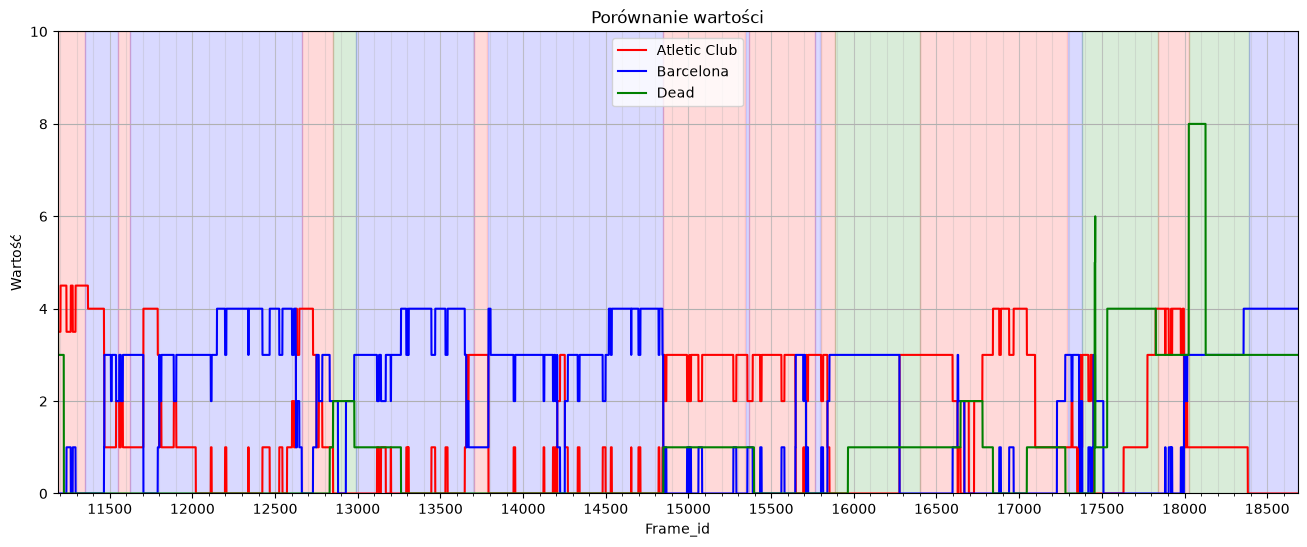

In [32]:
plt.figure(figsize=(16, 6))

plt.plot(atl_list, color='red', label='Atletic Club')
plt.plot(bar_list, color='blue', label='Barcelona')
plt.plot(dead_list, color='green', label='Dead')

plt.xlabel('Frame_id')
plt.ylabel('Wartość')
plt.title('Porównanie wartości')

ax = plt.gca()

# Siatka co 100
ax.xaxis.set_minor_locator(MultipleLocator(100))

# Napisy na osi X co 500
ax.xaxis.set_major_locator(MultipleLocator(500))

# Siatka główna i pomocnicza
ax.grid(which='major', axis='x', alpha=0.7)
ax.grid(which='minor', axis='x', alpha=0.3)

plt.axvspan(11185, 11350, color='red', alpha=0.15)
plt.axvspan(11351, 11552, color='blue', alpha=0.15)
plt.axvspan(11553, 11623, color='red', alpha=0.15)
plt.axvspan(11624, 12664, color='blue', alpha=0.15)
plt.axvspan(12665, 12850, color='red', alpha=0.15)
plt.axvspan(12851, 12988, color='green', alpha=0.15)
plt.axvspan(12989, 13703, color='blue', alpha=0.15)
plt.axvspan(13704, 13784, color='red', alpha=0.15)
plt.axvspan(13785, 14845, color='blue', alpha=0.15)
plt.axvspan(14846, 15345, color='red', alpha=0.15)
plt.axvspan(15346, 15364, color='blue', alpha=0.15)
plt.axvspan(15365, 15765, color='red', alpha=0.15)
plt.axvspan(15766, 15798, color='blue', alpha=0.15)
plt.axvspan(15799, 15888, color='red', alpha=0.15)
plt.axvspan(15889, 16399, color='green', alpha=0.15)
plt.axvspan(16400, 17292, color='red', alpha=0.15)
plt.axvspan(17293, 17379, color='blue', alpha=0.15)
plt.axvspan(17380, 17837, color='green', alpha=0.15)
plt.axvspan(17838, 18026, color='red', alpha=0.15)
plt.axvspan(18027, 18388, color='green', alpha=0.15)
plt.axvspan(18389, 18684, color='blue', alpha=0.15)

plt.xlim(11185, 18684)
plt.ylim(0,10)

plt.legend()
plt.grid(True)
plt.show()

In [33]:
def smooth_labels(df, max_length=100):
    df = df.copy()
    labels = df['label'].to_numpy()

    i = 0
    while i < len(labels):
        j = i + 1

        # Znajdź koniec ciągu identycznych etykiet
        while j < len(labels) and labels[j] == labels[i]:
            j += 1

        # Długość aktualnego ciągu
        length = j - i

        # Sprawdź, czy ciąg jest krótki i otoczony tą samą etykietą
        if (length <= max_length
            and i > 0
            and j < len(labels)
            and labels[i - 1] == labels[j]):

            labels[i:j] = labels[i - 1]

        i = j

    df['label'] = labels
    return df

answer = smooth_labels(answer)

In [34]:
answer.to_csv("evaluation/results/answer.csv", index=False)

In [35]:
!python evaluation/validate_submission.py evaluation/results/answer.csv

OK    answer.csv
      199319 rows, frame 0..199318

      label counts
        H    66138   33.2%
        A    43298   21.7%
        D    89883   45.1%
        X        0    0.0%

      reports 290 possessions of mean 15.1 s

Valid. Note this checks the format only -- it says nothing about whether the labels are right.
Score it against the public ground truth with run_evaluation.py.


In [36]:
sys.path.insert(0, os.path.abspath('../evaluation'))

gt = pm.label_codes(pm.read_label_csv('evaluation/gt/BAR-ATH_possession_gt_public.csv'))

def score(labels):
    """The two headline numbers, plus how many possessions the labels imply."""
    r = pm.evaluate(gt, pm.label_codes(labels))
    return {'macroF1': round(r['macro_f1'], 4), 'spellF1': round(r['spell_f1_mean'], 4),
            'possessions': r['n_pred_spells'],
            'mean_dur_s': round(r['mean_spell_duration_s'], 1)}

print('ground truth: 17 possessions of mean 14.2 s')
print(score(answer))

ground truth: 17 possessions of mean 14.2 s
{'macroF1': 0.7473, 'spellF1': 0.5161, 'possessions': 14, 'mean_dur_s': 19.2}


In [37]:
atl_full = np.zeros(len(answer))
bar_full = np.zeros(len(answer))
dead_full = np.zeros(len(answer))
for i in range(len(answer)):
    if answer.loc[i, "label"] == 'A':
        atl_full[i] = 1
    elif answer.loc[i, "label"] == 'H':
        bar_full[i] = 1
    else:
        dead_full[i] = 1

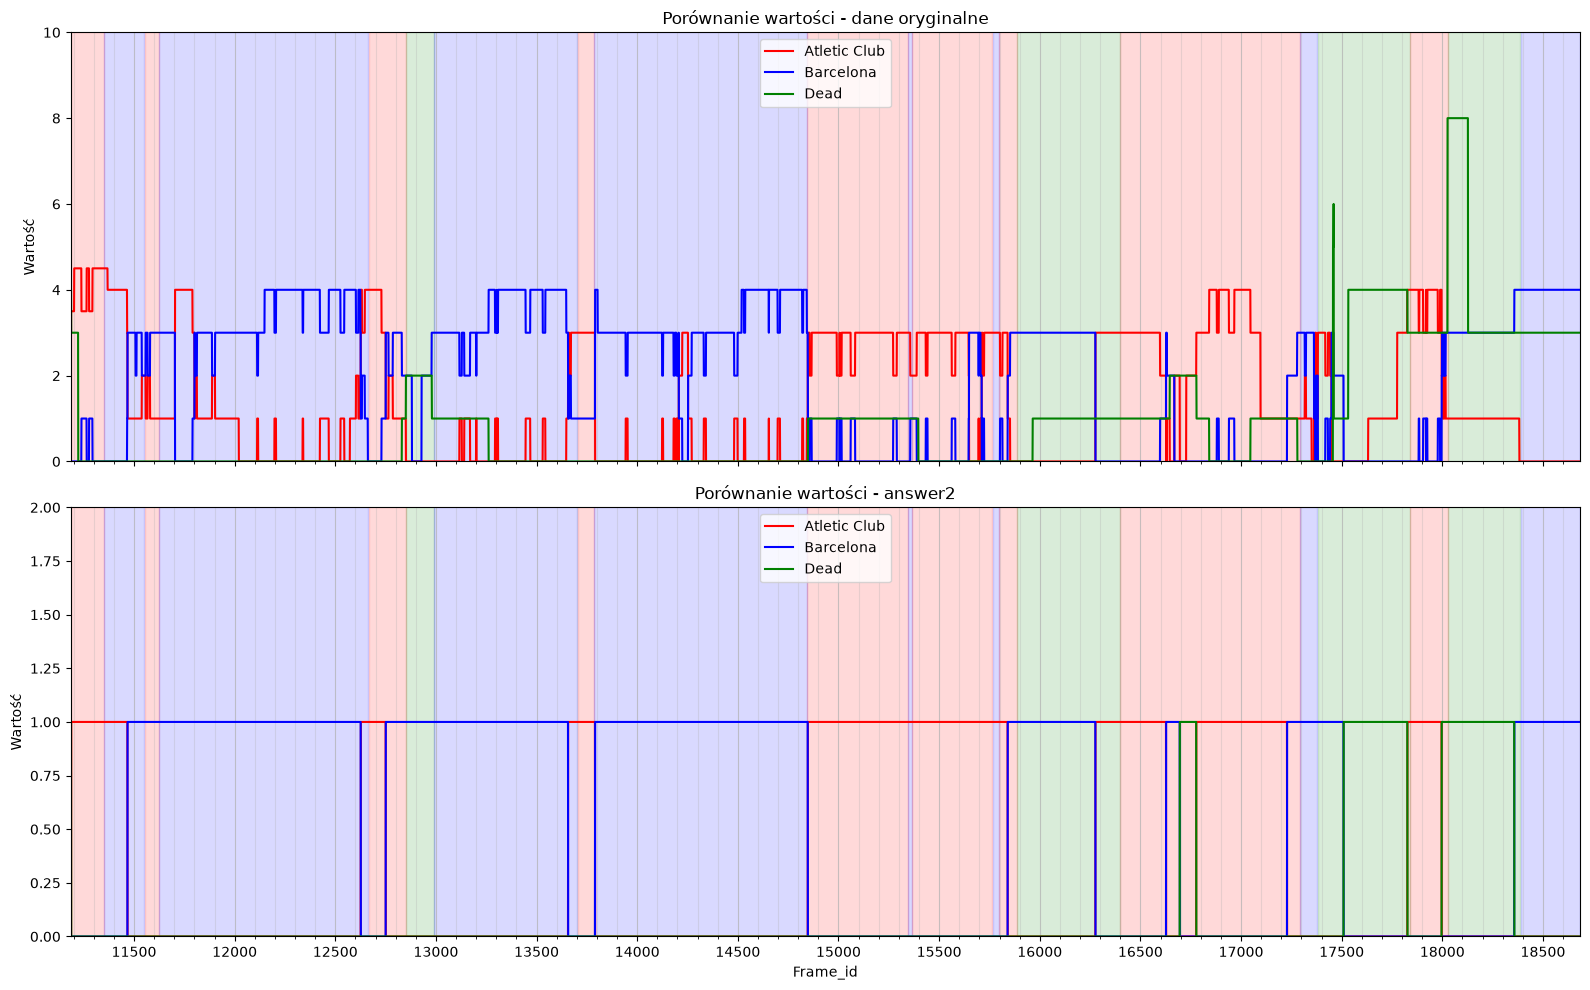

In [38]:
fig, (ax1, ax2) = plt.subplots(
    2, 1,
    figsize=(16, 10),
    sharex=True
)

# ==========================
# WYKRES 1
# ==========================

ax1.plot(atl_list, color='red', label='Atletic Club')
ax1.plot(bar_list, color='blue', label='Barcelona')
ax1.plot(dead_list, color='green', label='Dead')

ax1.set_ylabel('Wartość')
ax1.set_title('Porównanie wartości - dane oryginalne')
ax1.set_ylim(0, 10)
ax1.legend()

# ==========================
# WYKRES 2
# ==========================

ax2.plot(atl_full, color='red', label='Atletic Club')
ax2.plot(bar_full, color='blue', label='Barcelona')
ax2.plot(dead_full, color='green', label='Dead')

ax2.set_xlabel('Frame_id')
ax2.set_ylabel('Wartość')
ax2.set_title('Porównanie wartości - answer2')
ax2.set_ylim(0, 2)
ax2.legend()

# ==========================
# WSPÓLNE USTAWIENIA
# ==========================

for ax in [ax1, ax2]:

    ax.xaxis.set_minor_locator(MultipleLocator(100))
    ax.xaxis.set_major_locator(MultipleLocator(500))

    ax.grid(which='major', axis='x', alpha=0.7)
    ax.grid(which='minor', axis='x', alpha=0.3)

    ax.set_xlim(11185, 18684)

    # Zaznaczenia przedziałów
    ax.axvspan(11185, 11350, color='red', alpha=0.15)
    ax.axvspan(11351, 11552, color='blue', alpha=0.15)
    ax.axvspan(11553, 11623, color='red', alpha=0.15)
    ax.axvspan(11624, 12664, color='blue', alpha=0.15)
    ax.axvspan(12665, 12850, color='red', alpha=0.15)
    ax.axvspan(12851, 12988, color='green', alpha=0.15)
    ax.axvspan(12989, 13703, color='blue', alpha=0.15)
    ax.axvspan(13704, 13784, color='red', alpha=0.15)
    ax.axvspan(13785, 14845, color='blue', alpha=0.15)
    ax.axvspan(14846, 15345, color='red', alpha=0.15)
    ax.axvspan(15346, 15364, color='blue', alpha=0.15)
    ax.axvspan(15365, 15765, color='red', alpha=0.15)
    ax.axvspan(15766, 15798, color='blue', alpha=0.15)
    ax.axvspan(15799, 15888, color='red', alpha=0.15)
    ax.axvspan(15889, 16399, color='green', alpha=0.15)
    ax.axvspan(16400, 17292, color='red', alpha=0.15)
    ax.axvspan(17293, 17379, color='blue', alpha=0.15)
    ax.axvspan(17380, 17837, color='green', alpha=0.15)
    ax.axvspan(17838, 18026, color='red', alpha=0.15)
    ax.axvspan(18027, 18388, color='green', alpha=0.15)
    ax.axvspan(18389, 18684, color='blue', alpha=0.15)

plt.tight_layout()
plt.show()

# Pomysły

1) Przesunięcie set_pieces o te 250  

✔  v/  (zrobione, na pierwszych 5 min nie do sprawdzenia zbytnio)

2) Zmienienie wag przy różnych elementach w pętli for, gdzie liczymy atl,bar,dead

3) Inaczej rozstrzygać remisy: po pierwsze sprawdzać czy poprzedni element w ogóle jest wśród zwycięzców, po drugie można przy remisach dawać na dead ball (bo jest rzadziej) jako priorytet i dopiero potem na poprzedni element

✖  X (zrobione, nie działa, lepsza stara wersja)

4) 
Duże błędy: koło 12900 nie ma w ogóle dead ball, koło 16000-16500 nie ma dead ball (ale to wina danych), koło 16700 jest dead ball i atletic a nie powinno. 

Reszta mniejsze błędy: między 17200-17500 jest za długie niebieskie, nie ma drobnych posiadań czerwonych w 11600 niebieskich w 15400 i 15900 (ale to chyba musi być), za długie posiadanie czerwonych na początku.

5) Liczyć średnią całej funkcji atl, bar, dead w okolicy frame dla którego liczymy etykiete (np. średnia ze 100 ważonych, w zależności od odległości względem naszego frame) 